# ES Futures: Multi-Session OBI and OFI Signal Analysis

**FINM 37000 — From Order Book Imbalance to Executable Alpha**

This notebook evaluates whether top-of-book **order book imbalance (OBI)** and **order flow imbalance (OFI)** predict short-horizon E-mini S&P 500 (ES) futures midprice changes.

**Research design**
- **Instrument:** ES futures, regular trading hours, CME top-of-book data.
- **Research sample:** July 1–August 31, 2026 (43 trading sessions).
- **Model fitting:** First 32 sessions; **validation:** final 11 sessions (August 17–31).
- **Targets:** Forward midprice changes over 1, 5, 10, 30, and 60 seconds, in ES ticks.
- **Models:** OBI, OFI, and OBI + OFI, using simple linear regression.
- **Reserved final test:** September 2026 is **not used** for this analysis.

**Main question:** Does OFI add meaningful predictive information beyond OBI, and does the resulting signal appear economically actionable?

> **Reproducibility:** Run from the repository's configured Python environment. The raw and processed market data are stored locally under `data/` and are not committed to Git. The 43-session processing step is computationally expensive; the resulting one-second panel is saved for reuse.


## 1. Imports and research setup

Use the project's existing data-cleaning, feature-engineering, and OFI research functions rather than duplicating their implementations.


In [1]:
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from finm37000_grp2.config import PROCESSED_DIR
from finm37000_grp2.data.clean import book_states, read_clean
from finm37000_grp2.features import calculate_obi
from finm37000_grp2.ofi_analysis import (
    chronological_split,
    daily_slopes,
    make_research_frame,
)

## 2. Construct and validate one session

Start with July 1 to confirm the signals align at the **one-second** level. OFI is aggregated from quote updates; OBI is sampled from the last available book state in each second. The forward return is measured from the corresponding second-end midprice.


In [2]:
# Load one trading session
day = "2026-07-01"

df = read_clean(day)
quotes = book_states(df)

# Calculate OFI and forward price movements
panel = make_research_frame(quotes)

# Calculate OBI using the final book state in each second
obi = calculate_obi(quotes["bid_sz"], quotes["ask_sz"])

obi_by_second = (
    pd.DataFrame(
        {
            "obi": obi,
            "second_start_utc": quotes.index.floor("s"),
        }
    )
    .groupby("second_start_utc")["obi"]
    .last()
)

# Align OBI with the OFI panel
panel = panel.merge(
    obi_by_second,
    on="second_start_utc",
    how="left",
)

print(panel.shape)
print(
    panel[["second_start_utc", "obi", "ofi_1s", "fwd_1s_ticks", "fwd_5s_ticks"]].head()
)

(24300, 14)
           second_start_utc       obi  ofi_1s  fwd_1s_ticks  fwd_5s_ticks
0 2026-07-01 13:30:00+00:00 -0.032258    56.0           2.0          -4.0
1 2026-07-01 13:30:01+00:00 -0.294118    22.0           2.0          -8.0
2 2026-07-01 13:30:02+00:00 -0.750000    73.0          -9.0         -11.0
3 2026-07-01 13:30:03+00:00  0.800000  -298.0           5.0         -12.0
4 2026-07-01 13:30:04+00:00 -0.764706   142.0          -4.0         -18.0


### 2.1 Data quality and timestamp checks

Check missing features, the expected OBI range of −1 to +1, and duplicate second timestamps. Missing forward returns near the end of a session are expected because future observations are unavailable.


In [4]:
# Check signal completeness and alignment
print("Missing values:")
print(
    panel[
        [
            "obi",
            "ofi_1s",
            "ofi_5s",
            "fwd_1s_ticks",
            "fwd_5s_ticks",
            "fwd_10s_ticks",
            "fwd_30s_ticks",
            "fwd_60s_ticks",
        ]
    ]
    .isna()
    .sum()
)

print("\nOBI range:")
print(panel["obi"].min(), panel["obi"].max())

print("\nDuplicate timestamps:")
print(panel["second_start_utc"].duplicated().sum())

Missing values:
obi               1
ofi_1s            0
ofi_5s            4
fwd_1s_ticks      1
fwd_5s_ticks      5
fwd_10s_ticks    10
fwd_30s_ticks    30
fwd_60s_ticks    60
dtype: int64

OBI range:
-0.9696969696969697 0.9811320754716981

Duplicate timestamps:
0


## 3. Build the 43-session research panel

Process each trading day separately to limit memory usage. Merge the daily OBI snapshot into the OFI one-second panel, then concatenate the resulting daily panels. This stage can take several minutes.


In [ ]:
files = sorted((PROCESSED_DIR / "ES").glob("*.parquet"))
files = [f for f in files if "2026-07-01" <= f.stem <= "2026-08-31"]

panels = []

for i, file in enumerate(files, 1):
    day = file.stem

    df = read_clean(day)
    quotes = book_states(df)

    daily_panel = make_research_frame(quotes)

    obi = calculate_obi(quotes["bid_sz"], quotes["ask_sz"])

    obi_by_second = (
        pd.DataFrame(
            {
                "obi": obi,
                "second_start_utc": quotes.index.floor("s"),
            }
        )
        .groupby("second_start_utc")["obi"]
        .last()
    )

    daily_panel = daily_panel.merge(
        obi_by_second,
        on="second_start_utc",
        how="left",
    )

    panels.append(daily_panel)

    del df, quotes, daily_panel, obi, obi_by_second
    gc.collect()

    print(f"[{i}/{len(files)}] Processed {day}", flush=True)

# Combine the one-second panels
all_data = pd.concat(panels, ignore_index=True)

print("\nCombined dataset:", all_data.shape)
print("Sessions:", all_data["session_id"].nunique())

[1/43] Processed 2026-07-01
[2/43] Processed 2026-07-02
[3/43] Processed 2026-07-06
[4/43] Processed 2026-07-07
[5/43] Processed 2026-07-08
[6/43] Processed 2026-07-09
[7/43] Processed 2026-07-10
[8/43] Processed 2026-07-13
[9/43] Processed 2026-07-14
[10/43] Processed 2026-07-15
[11/43] Processed 2026-07-16
[12/43] Processed 2026-07-17
[13/43] Processed 2026-07-20
[14/43] Processed 2026-07-21
[15/43] Processed 2026-07-22
[16/43] Processed 2026-07-23
[17/43] Processed 2026-07-24
[18/43] Processed 2026-07-27
[19/43] Processed 2026-07-28
[20/43] Processed 2026-07-29
[21/43] Processed 2026-07-30
[22/43] Processed 2026-07-31
[23/43] Processed 2026-08-03
[24/43] Processed 2026-08-04
[25/43] Processed 2026-08-05
[26/43] Processed 2026-08-06
[27/43] Processed 2026-08-07
[28/43] Processed 2026-08-10
[29/43] Processed 2026-08-11
[30/43] Processed 2026-08-12
[31/43] Processed 2026-08-13
[32/43] Processed 2026-08-14
[33/43] Processed 2026-08-17
[34/43] Processed 2026-08-18
[35/43] Processed 2026-

### 3.1 Save the processed signal panel

Cache the combined data locally so subsequent analysis does not require rereading millions of event-level quote updates.


In [7]:
output_path = PROCESSED_DIR / "ES" / "in_sample_signals.parquet"

all_data.to_parquet(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", all_data.shape)

Saved to: /Users/kayla/Futures/finm37000-grp-2/data/processed/ES/in_sample_signals.parquet
Dataset shape: (1044900, 14)


### 3.2 Verify that the saved panel can be reloaded

This read-back check confirms that the saved file is usable. **Note:** it does not skip the processing cell above during a full notebook run.


In [2]:
output_path = PROCESSED_DIR / "ES" / "in_sample_signals.parquet"

if output_path.exists():
    all_data = pd.read_parquet(output_path)
    print("Loaded saved dataset:", all_data.shape)
else:
    print("Saved dataset not found.")

Loaded saved dataset: (1044900, 14)


## 4. Chronological training and validation

Split **by trading session**, not by randomly shuffled seconds. The first 32 sessions are used to fit the models; the remaining 11 August sessions are used to evaluate them. September is held back for the project's final out-of-sample backtest.


In [3]:
# Split the 43 in-sample sessions chronologically
train, test = chronological_split(all_data, test_fraction=0.25)

print("Training sessions:", train["session_id"].nunique())
print("Validation sessions:", test["session_id"].nunique())

print("\nTraining period:")
print(train["session_id"].min(), "to", train["session_id"].max())

print("\nValidation period:")
print(test["session_id"].min(), "to", test["session_id"].max())

print("\nObservations:")
print("Training:", len(train))
print("Validation:", len(test))

Training sessions: 32
Validation sessions: 11

Training period:
2026-07-01 to 2026-08-14

Validation period:
2026-08-17 to 2026-08-31

Observations:
Training: 777600
Validation: 267300


## 5. Compare predictive models

All models forecast forward **midprice movement in ticks**, not realized trade P&L. Validation R² measures improvement over a constant-mean benchmark; correlation measures directional co-movement, while MAE measures absolute forecast error.


### 5.1 One-second horizon

Compare OBI alone, OFI alone, and their joint specification. The key incremental-value question is whether **OBI + OFI** improves on **OBI** when evaluated on the same held-out sessions.


In [4]:
target = "fwd_1s_ticks"

models = {
    "OBI": ["obi"],
    "OFI": ["ofi_1s"],
    "OBI + OFI": ["obi", "ofi_1s"],
}

results = []

for name, features in models.items():
    # Keep only observations with valid features and targets
    train_data = train[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()

    test_data = test[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()

    model = LinearRegression()
    model.fit(train_data[features], train_data[target])

    predictions = model.predict(test_data[features])

    results.append(
        {
            "Model": name,
            "Validation R²": r2_score(test_data[target], predictions),
            "Correlation": np.corrcoef(predictions, test_data[target])[0, 1],
            "MAE (ticks)": np.mean(np.abs(test_data[target] - predictions)),
        }
    )

results_df = pd.DataFrame(results)
print(results_df.round(6))

       Model  Validation R²  Correlation  MAE (ticks)
0        OBI       0.042080     0.205189     0.553425
1        OFI       0.000403     0.022274     0.497120
2  OBI + OFI       0.042850     0.207042     0.553553


### 5.2 Signal performance across forecast horizons

Repeat the comparison for 1, 5, 10, 30, and 60 seconds to assess how rapidly predictive power declines. Longer-horizon forward returns overlap across adjacent seconds, so observations should not be treated as independent.


In [5]:
horizons = [1, 5, 10, 30, 60]
horizon_results = []

for h in horizons:
    target = f"fwd_{h}s_ticks"

    for name, features in models.items():
        train_data = (
            train[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()
        )

        test_data = (
            test[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()
        )

        model = LinearRegression()
        model.fit(train_data[features], train_data[target])

        predictions = model.predict(test_data[features])

        horizon_results.append(
            {
                "Horizon (s)": h,
                "Model": name,
                "Validation R²": r2_score(test_data[target], predictions),
                "Correlation": np.corrcoef(predictions, test_data[target])[0, 1],
                "MAE (ticks)": np.mean(np.abs(test_data[target] - predictions)),
            }
        )

horizon_df = pd.DataFrame(horizon_results)

print(
    horizon_df.pivot(
        index="Horizon (s)",
        columns="Model",
        values="Validation R²",
    ).round(6)
)

Model             OBI  OBI + OFI       OFI
Horizon (s)                               
1            0.042080   0.042850  0.000403
5            0.009855   0.009964  0.000031
10           0.004713   0.004749 -0.000035
30           0.001466   0.001472 -0.000112
60           0.000750   0.000753 -0.000234


## 6. Visual evidence

The following figures show three complementary aspects of the signal: **predictive decay**, **directional ordering**, and **stability across trading days**.


### 6.1 Predictive decay: validation R² by horizon

A sharp decline at longer horizons indicates that the relationship is short-lived. A positive R² alone does not imply a profitable execution strategy.


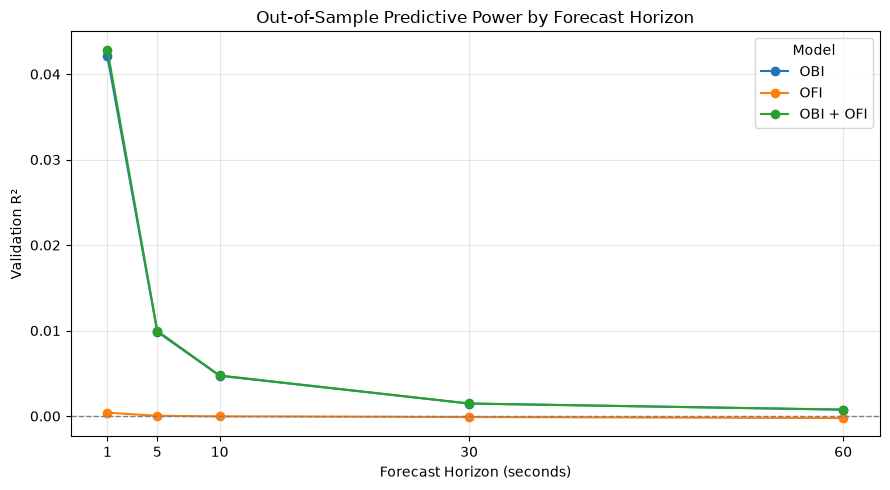

In [6]:
pivot = horizon_df.pivot(
    index="Horizon (s)",
    columns="Model",
    values="Validation R²",
)

ax = pivot[["OBI", "OFI", "OBI + OFI"]].plot(
    marker="o",
    figsize=(9, 5),
)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Out-of-Sample Predictive Power by Forecast Horizon")
ax.set_xlabel("Forecast Horizon (seconds)")
ax.set_ylabel("Validation R²")
ax.set_xticks([1, 5, 10, 30, 60])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2 OBI deciles and next-second returns

Define the decile boundaries using **training data only**, then apply those fixed boundaries to validation observations. A consistent increase in mean forward returns across deciles supports a directional association between OBI and subsequent midprice movement.


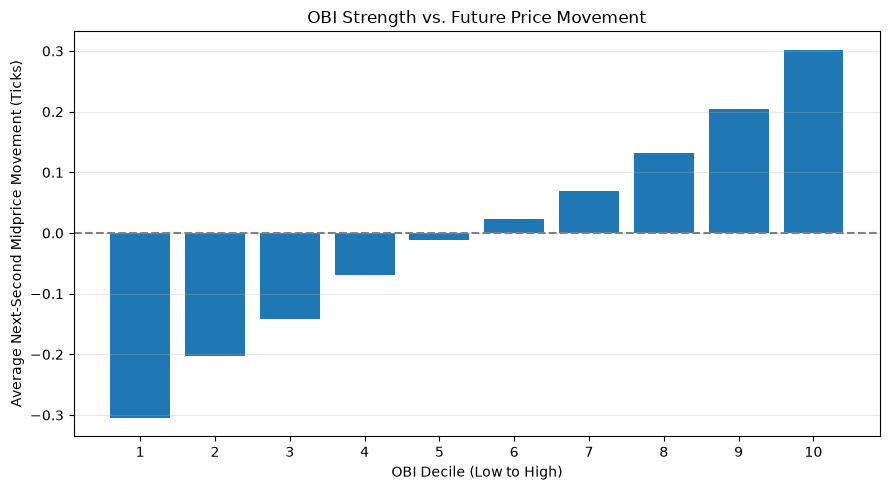

   decile  mean_return  count  mean_obi
0       1      -0.3050  26917   -0.6704
1       2      -0.2019  29423   -0.4421
2       3      -0.1423  28214   -0.2966
3       4      -0.0689  26731   -0.1707
4       5      -0.0110  25118   -0.0514
5       6       0.0224  21654    0.0585
6       7       0.0698  25322    0.1684
7       8       0.1312  28231    0.2936
8       9       0.2048  29173    0.4411
9      10       0.3020  26289    0.6694


In [7]:
# Define OBI deciles using training data only
target = "fwd_1s_ticks"

edges = np.unique(np.quantile(train["obi"].dropna(), np.linspace(0, 1, 11)))
edges[0] = -np.inf
edges[-1] = np.inf

# Apply the same decile boundaries to validation data
decile_data = test[["obi", target]].dropna().copy()

decile_data["decile"] = (
    pd.cut(
        decile_data["obi"],
        bins=edges,
        labels=False,
        include_lowest=True,
    )
    + 1
)

decile_summary = (
    decile_data.groupby("decile")
    .agg(
        mean_return=(target, "mean"),
        count=(target, "size"),
        mean_obi=("obi", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.bar(decile_summary["decile"], decile_summary["mean_return"])
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("OBI Decile (Low to High)")
plt.ylabel("Average Next-Second Midprice Movement (Ticks)")
plt.title("OBI Strength vs. Future Price Movement")
plt.xticks(decile_summary["decile"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(decile_summary.round(4))

## 7. Economic relevance: spread versus predicted movement

A short-horizon midprice prediction must be interpreted alongside the cost of entering and exiting a position. This diagnostic measures the **July 1** quoted spread at the event level; it is an illustrative check, **not** a complete validation-period cost estimate or an executable backtest.


In [8]:
# Reload July 1 book states
df = read_clean("2026-07-01")
quotes = book_states(df)

# Calculate the bid-ask spread in ES ticks
spread_ticks = (quotes["ask_px"] - quotes["bid_px"]) / 0.25

print("Average spread (ticks):", spread_ticks.mean())
print("Median spread (ticks):", spread_ticks.median())
print("Percentage with 1-tick spread:", (spread_ticks == 1).mean() * 100)

Average spread (ticks): 1.0467399580628876
Median spread (ticks): 1.0
Percentage with 1-tick spread: 95.39139334009543


## 8. Stability across validation sessions

Estimate a separate OBI-to-next-second-return slope for each of the 11 validation days. Consistently positive slopes provide evidence that the relationship is not confined to one unusual session, although they do not establish independence or tradability.


In [9]:
daily_results = daily_slopes(
    test,
    signal="obi",
    target="fwd_1s_ticks",
)

print(daily_results.round(4))
print("\nColumns:", daily_results.columns.tolist())

    session_id   slope      n
0   2026-08-17  0.4201  24274
1   2026-08-18  0.4390  24285
2   2026-08-19  0.4726  24283
3   2026-08-20  0.4966  24294
4   2026-08-21  0.4496  24270
5   2026-08-24  0.4325  24292
6   2026-08-25  0.4667  24259
7   2026-08-26  0.4183  24257
8   2026-08-27  0.4503  24282
9   2026-08-28  0.4667  24291
10  2026-08-31  0.4569  24285

Columns: ['session_id', 'slope', 'n']


### 8.1 Daily slope summary

Summarize the mean, variation, and number of positive daily slopes.


In [10]:
print("Mean daily slope:", round(daily_results["slope"].mean(), 4))
print("Std. deviation:", round(daily_results["slope"].std(), 4))
print("Positive days:", (daily_results["slope"] > 0).sum())
print("Total days:", len(daily_results))

Mean daily slope: 0.4518
Std. deviation: 0.0236
Positive days: 11
Total days: 11


### 8.2 Daily stability visualization

The dashed horizontal line shows the mean daily slope; the zero line indicates the absence of a positive linear relationship.


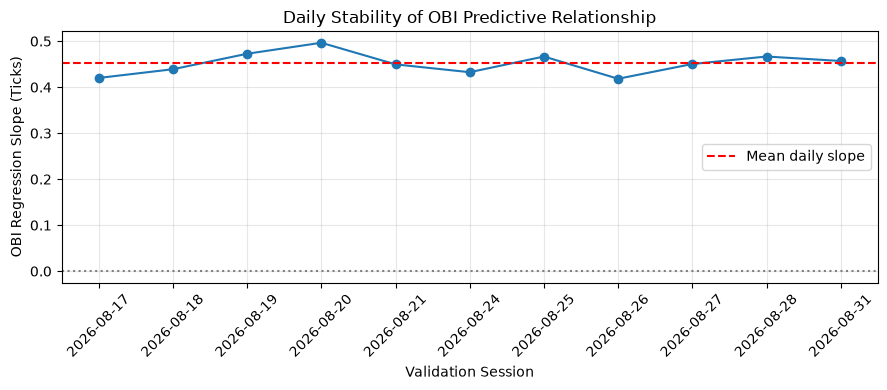

In [11]:
plt.figure(figsize=(9, 4))

plt.plot(
    daily_results["session_id"],
    daily_results["slope"],
    marker="o",
)

plt.axhline(
    daily_results["slope"].mean(),
    color="red",
    linestyle="--",
    label="Mean daily slope",
)

plt.axhline(0, color="gray", linestyle=":")

plt.title("Daily Stability of OBI Predictive Relationship")
plt.xlabel("Validation Session")
plt.ylabel("OBI Regression Slope (Ticks)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Key Findings and Limitations

### Key Findings

1. **OBI provides stronger short-horizon predictive information than OFI.** At the 1-second horizon, OBI achieves a validation R² of 0.0421, compared with 0.0004 for OFI.

2. **Predictive power decays rapidly.** OBI's validation R² decreases from 0.0421 at 1 second to 0.0099 at 5 seconds and 0.0008 at 60 seconds.

3. **Combining OBI and OFI provides only marginal improvement.** The combined model achieves a 1-second validation R² of 0.0429, suggesting limited incremental predictive information from OFI.

4. **OBI exhibits a monotonic relationship with future price movements.** Average next-second midprice movements increase from approximately -0.305 ticks in the lowest OBI decile to +0.302 ticks in the highest decile.

5. **The predictive relationship is stable across validation sessions.** OBI regression slopes are positive on all 11 validation days, with a mean of 0.4518 and standard deviation of 0.0236.

### Limitations

- **Trading costs:** On July 1, the event-level quoted spread averages approximately 1.047 ticks, whereas the extreme validation OBI deciles have mean next-second midprice movements of about ±0.30 ticks. These are different samples and measurement levels, so this is an illustrative comparison, not a full transaction-cost test.
- **Validation period:** Results are based on 11 held-out August sessions within the July–August research period. September remains reserved for the final out-of-sample backtest.
- **Market conditions:** Results may vary across different volatility and liquidity environments.
- **Statistical dependence:** Consecutive one-second observations are not independent, particularly when evaluating overlapping forward-return horizons.
- **Execution assumptions:** The analysis predicts midprice changes and does not yet model order fills, transaction fees, slippage, or market impact.

### Conclusion

Order book imbalance demonstrates consistent, short-lived predictive information for ES futures midprice movements. Order flow imbalance provides comparatively little additional predictive value in the current linear models. Although the statistical relationship is encouraging, its economic value remains uncertain until execution costs and trading constraints are incorporated.